# Temperature Analysis and Prediction for India (1901–2021)
**Machine Learning Application Project**

## 1. Problem framing
**Question.** How fast has India's mean temperature been rising, has the warming accelerated in recent decades, and how well can simple regression models *forecast* future years?

**Task type.** Supervised regression on a time-ordered series with one predictor (`YEAR`). Targets: `ANNUAL` and four seasonal means (`JAN-FEB`, `MAR-MAY`, `JUN-SEP`, `OCT-DEC`), in °C.

**Two different goals are kept separate in this notebook:**
1. *Description / inference* (Sections 4, 6, 7): trend and acceleration estimates fitted on all 121 years.
2. *Prediction* (Section 5): models are tuned using only the past and judged once on a later, untouched test period, and they must beat a simple baseline.

**Dataset.** `TEMP_ANNUAL_SEASONAL_MEAN.csv`, 121 yearly rows (1901–2021).
> **TODO (author):** add the original source, publisher, download URL and access date of this dataset here and in the README.

**How to run.** Put the CSV in the same folder as this notebook, install `requirements.txt`, and run all cells from top to bottom. Every number and figure below is produced by the code.

## 2. Setup and data loading

In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, FunctionTransformer
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42                      # no randomised step is used below; fixed for completeness
np.random.seed(SEED)
pd.set_option("display.precision", 4)

DATA_FILE = "TEMP_ANNUAL_SEASONAL_MEAN.csv"
if not os.path.exists(DATA_FILE):
    # Google Colab fallback: upload the CSV when it is not next to the notebook
    from google.colab import files
    uploaded = files.upload()
    DATA_FILE = list(uploaded.keys())[0]

raw = pd.read_csv(DATA_FILE)
print("Raw shape:", raw.shape)
raw.tail(4)

Raw shape: (123, 6)


,YEAR,ANNUAL,JAN-FEB,MAR-MAY,JUN-SEP,OCT-DEC
119,2020.0,25.78,20.79,27.58,28.45,23.75
120,2021.0,25.93,21.43,27.97,28.36,23.66
121,NaN,NaN,NaN,NaN,NaN,NaN
122,NaN,ANNUAL,JAN-FEB,MAR-MAY,JUN-SEP,OCT-DEC


## 3. Data cleaning
The raw file ends with an empty row and a repeated header row, so the last rows are not numeric. They are removed once, and the result is checked: no missing values, and exactly one row for every year from 1901 to 2021.

In [21]:
temperature_columns = ["ANNUAL", "JAN-FEB", "MAR-MAY", "JUN-SEP", "OCT-DEC"]

df = raw.apply(pd.to_numeric, errors="coerce")
n_dropped = int(df.isna().any(axis=1).sum())
df = df.dropna().sort_values("YEAR").reset_index(drop=True)
df["YEAR"] = df["YEAR"].astype(int)

assert df.isna().sum().sum() == 0
assert df["YEAR"].is_unique
assert (df["YEAR"].diff().dropna() == 1).all(), "years are not consecutive"

print(f"Rows dropped (blank / repeated-header rows): {n_dropped}")
print(f"Clean shape: {df.shape}  |  years {df.YEAR.min()}–{df.YEAR.max()}")
df.head()

Rows dropped (blank / repeated-header rows): 2
Clean shape: (121, 6)  |  years 1901–2021


,YEAR,ANNUAL,JAN-FEB,MAR-MAY,JUN-SEP,OCT-DEC
0,1901,25.42,20.11,27.64,28.16,23.10
1,1902,25.42,20.88,27.96,27.98,22.51
2,1903,25.01,19.99,27.02,28.00,22.33
3,1904,24.93,19.76,27.23,27.57,22.56
4,1905,24.84,18.36,26.38,28.20,23.13


## 4. Exploratory data analysis

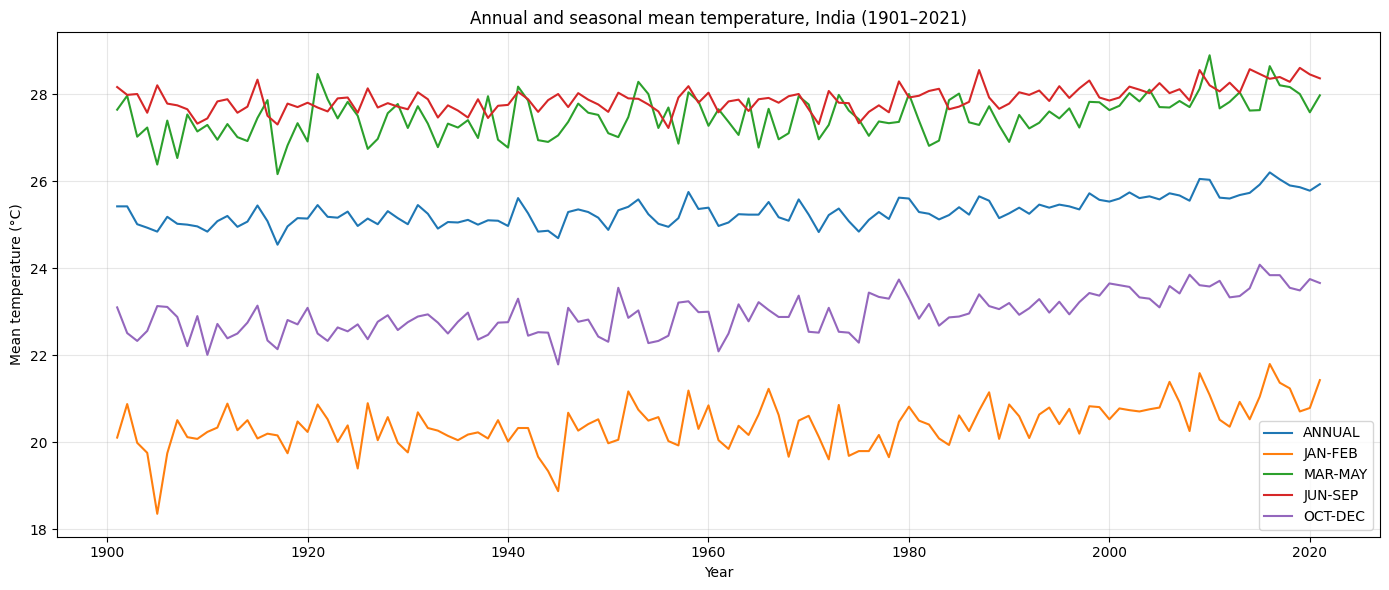

In [22]:
plt.figure(figsize=(14, 6))
for col in temperature_columns:
    plt.plot(df["YEAR"], df[col], label=col, linewidth=1.5)
plt.xlabel("Year"); plt.ylabel("Mean temperature (°C)")
plt.title("Annual and seasonal mean temperature, India (1901–2021)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

Descriptive statistics


,count,Mean,Std dev,Min,25%,50%,75%,Max
ANNUAL,121.0,25.304,0.316,24.54,25.08,25.25,25.55,26.20
JAN-FEB,121.0,20.400,0.520,18.36,20.09,20.41,20.75,21.80
MAR-MAY,121.0,27.478,0.465,26.16,27.14,27.47,27.82,28.89
JUN-SEP,121.0,27.889,0.286,27.22,27.70,27.88,28.05,28.60
OCT-DEC,121.0,22.955,0.461,21.79,22.55,22.94,23.30,24.08


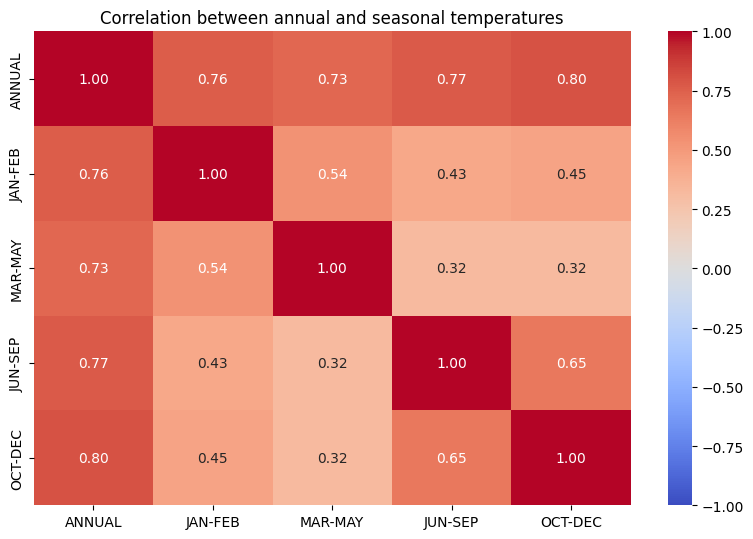

In [23]:
summary = df[temperature_columns].describe().T
summary = summary.rename(columns={"mean": "Mean", "std": "Std dev", "min": "Min", "max": "Max"})
print("Descriptive statistics")
display(summary.round(3))

corr = df[temperature_columns].corr()
plt.figure(figsize=(8, 5.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation between annual and seasonal temperatures")
plt.tight_layout(); plt.show()

### 4.1 Full-period linear trend (descriptive)
Ordinary least squares of temperature on time, with HAC (Newey–West) standard errors because yearly climate data are autocorrelated. These R² values are **in-sample** and only describe how much of the variation a straight line explains; they are *not* a measure of forecast skill (see Section 5).

,Series,Trend (°C/decade),95% CI low,95% CI high,HAC p-value,In-sample R²
0,ANNUAL,0.0628,0.0449,0.0806,0.0,0.4842
1,JAN-FEB,0.0705,0.0439,0.0970,0.0,0.2259
2,MAR-MAY,0.0572,0.0347,0.0797,0.0,0.1860
3,JUN-SEP,0.0431,0.0241,0.0622,0.0,0.2795
4,OCT-DEC,0.0896,0.0678,0.1113,0.0,0.4650


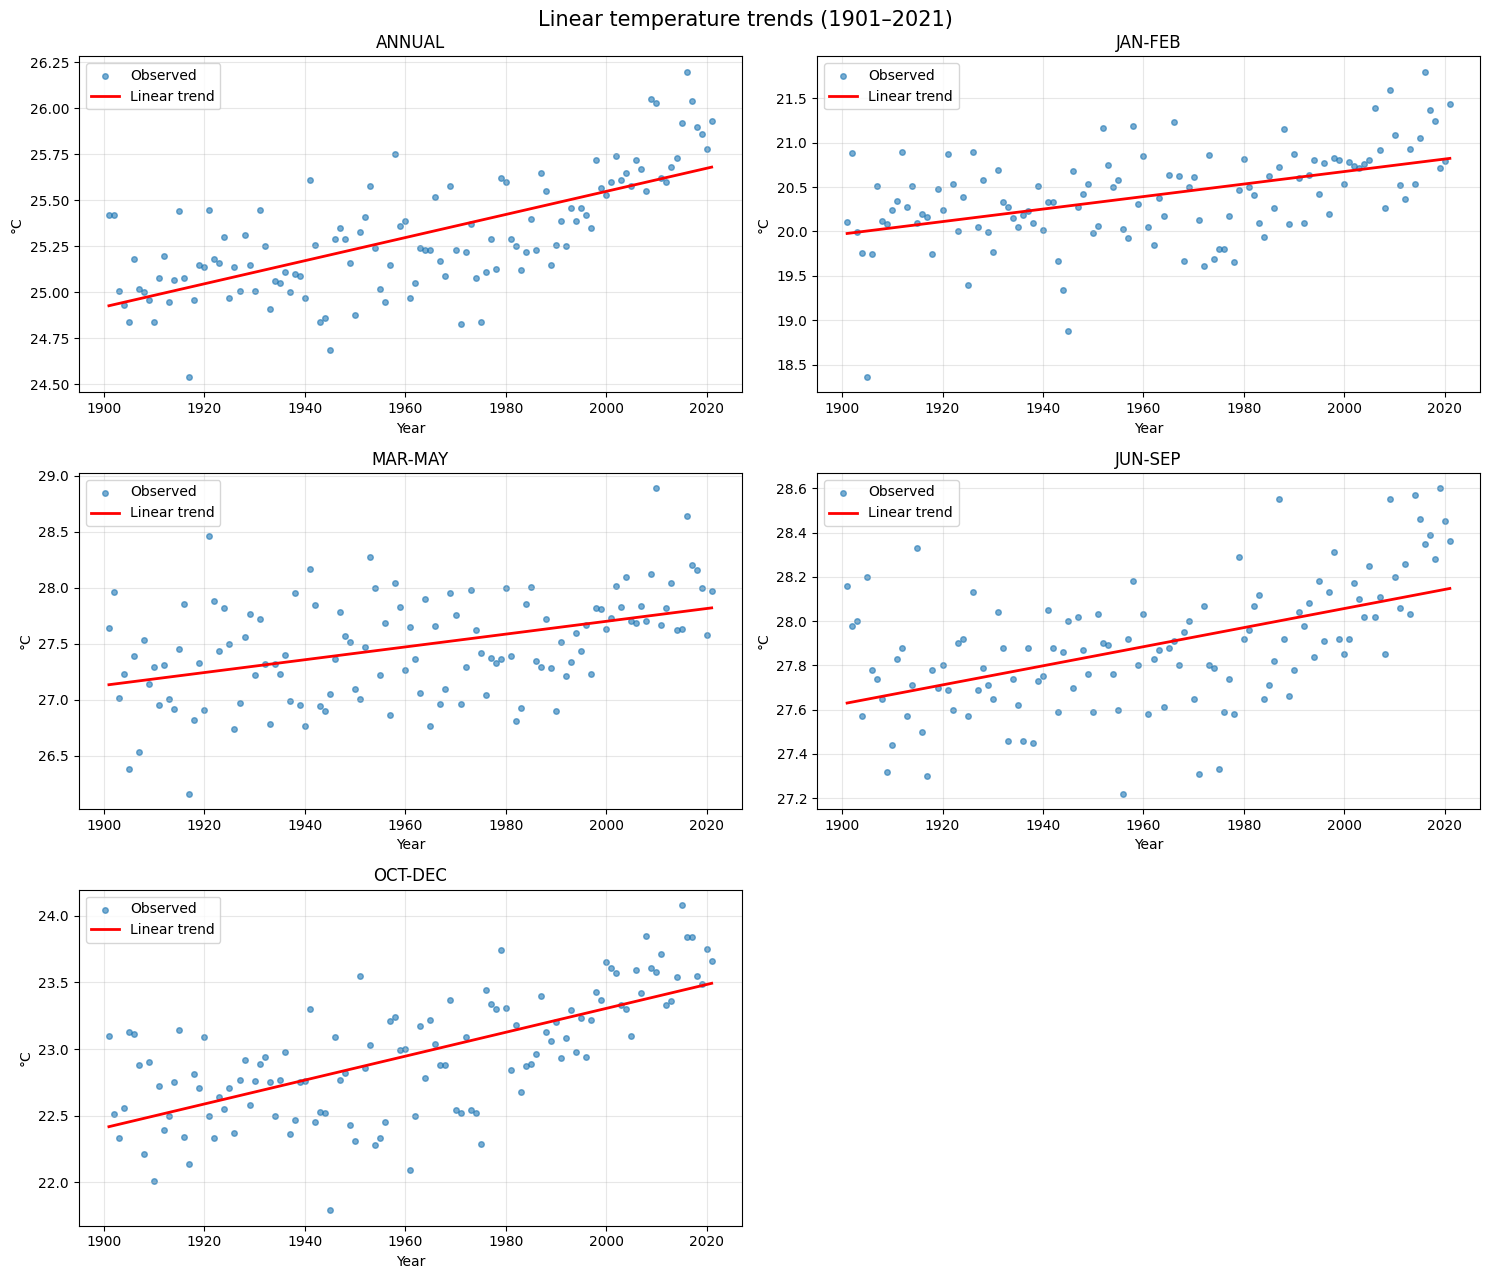

In [24]:
rows = []
for col in temperature_columns:
    X = sm.add_constant((df["YEAR"] - 1901) / 10)          # time in decades
    fit = sm.OLS(df[col], X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    slope, ci = fit.params.iloc[1], fit.conf_int().iloc[1]
    rows.append({"Series": col,
                 "Trend (°C/decade)": slope,
                 "95% CI low": ci.iloc[0], "95% CI high": ci.iloc[1],
                 "HAC p-value": fit.pvalues.iloc[1],
                 "In-sample R²": fit.rsquared})
full_trends = pd.DataFrame(rows)
display(full_trends.round(4))

fig, axes = plt.subplots(3, 2, figsize=(15, 13)); axes = axes.flatten()
for i, col in enumerate(temperature_columns):
    b = np.polyfit(df["YEAR"], df[col], 1)
    axes[i].scatter(df["YEAR"], df[col], s=16, alpha=0.6, label="Observed")
    axes[i].plot(df["YEAR"], np.polyval(b, df["YEAR"]), color="red", lw=2, label="Linear trend")
    axes[i].set_title(col); axes[i].set_xlabel("Year"); axes[i].set_ylabel("°C")
    axes[i].grid(alpha=0.3); axes[i].legend()
fig.delaxes(axes[5]); plt.suptitle("Linear temperature trends (1901–2021)", fontsize=15)
plt.tight_layout(); plt.show()

## 5. Predictive modelling and validation
**Design (chosen before looking at test results):**
- **Chronological split.** Train on 1901–2001, hold out the **last 20 years (2002–2021)** as a test set that is used **once**, at the end. No shuffling, because the data are a time series.
- **Model selection on the training period only**, with `TimeSeriesSplit` (5 expanding-window folds, 10 validation years each). Candidates: Ridge polynomial regression (degree 1–3, several α) and a continuous piecewise-linear model with a slope change at 1981.
- **Baseline.** The training-period mean (a "no-trend" model), and a plain linear trend. A model is only useful if it beats these on the test period.
- **Metrics on the test period:** MAE, RMSE and R². R² is computed against the *test-period* mean, so it can be negative when a model is worse than predicting that mean.

The 1981 breakpoint was chosen from domain knowledge and checked for sensitivity in Section 6; it lies inside the training period.

In [25]:
TEST_YEARS = 20
train, test = df.iloc[:-TEST_YEARS], df.iloc[-TEST_YEARS:]
print(f"Train: {train.YEAR.min()}–{train.YEAR.max()} ({len(train)} yrs)   Test: {test.YEAR.min()}–{test.YEAR.max()} ({len(test)} yrs)")

to_decades = lambda d: ((d[["YEAR"]] - 1901) / 10).values
X_train, X_test = to_decades(train), to_decades(test)

BREAK_YEAR = 1981
KNOT = (BREAK_YEAR - 1901) / 10

def add_hinge(X, knot):
    # columns: time, and extra slope after the knot (continuous piecewise-linear model)
    return np.hstack([X, np.maximum(X - knot, 0)])

def make_model(kind, degree=None, alpha=1.0):
    if kind == "poly":
        return make_pipeline(PolynomialFeatures(degree, include_bias=False),
                             StandardScaler(), Ridge(alpha=alpha))
    if kind == "piecewise":
        return make_pipeline(FunctionTransformer(add_hinge, kw_args={"knot": KNOT}),
                             Ridge(alpha=alpha))
    raise ValueError(kind)

ALPHAS = [0.001, 0.1, 1, 10]
candidates = [("poly", d, a) for d in (1, 2, 3) for a in ALPHAS] + \
             [("piecewise", None, a) for a in (0.001, 0.1, 1)]
label = lambda k, d: f"poly deg {d}" if k == "poly" else f"piecewise ({BREAK_YEAR})"

tscv = TimeSeriesSplit(n_splits=5, test_size=10)

cv_rows = []
for col in temperature_columns:
    y_tr = train[col].values
    for kind, deg, alpha in candidates:
        s = cross_validate(make_model(kind, deg, alpha), X_train, y_tr, cv=tscv,
                           scoring="neg_root_mean_squared_error")
        cv_rows.append({"Series": col, "Model": label(kind, deg), "kind": kind,
                        "degree": deg, "alpha": alpha,
                        "CV RMSE": -s["test_score"].mean(),
                        "CV RMSE std": s["test_score"].std()})
cv_table = pd.DataFrame(cv_rows)

# Model selection uses the CV table only (never the test set)
selected = cv_table.loc[cv_table.groupby("Series")["CV RMSE"].idxmin()].reset_index(drop=True)
selected = selected.set_index("Series").loc[temperature_columns].reset_index()
print("Selected by time-series cross-validation on 1901–2001 only:")
display(selected[["Series", "Model", "alpha", "CV RMSE", "CV RMSE std"]].round(4))

Train: 1901–2001 (101 yrs)   Test: 2002–2021 (20 yrs)
Selected by time-series cross-validation on 1901–2001 only:


,Series,Model,alpha,CV RMSE,CV RMSE std
0,ANNUAL,piecewise (1981),0.001,0.1995,0.0599
1,JAN-FEB,piecewise (1981),1.000,0.4445,0.1067
2,MAR-MAY,poly deg 1,10.000,0.3742,0.1022
3,JUN-SEP,piecewise (1981),1.000,0.2326,0.0494
4,OCT-DEC,poly deg 2,1.000,0.3191,0.0921


In [26]:
# ---- One-time evaluation on the untouched test period ----
def scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R²": r2_score(y_true, y_pred)}

test_rows, test_preds = [], {}
for _, r in selected.iterrows():
    col = r["Series"]
    y_tr, y_te = train[col].values, test[col].values

    sel = make_model(r["kind"], None if pd.isna(r["degree"]) else int(r["degree"]), r["alpha"]).fit(X_train, y_tr)
    base = DummyRegressor(strategy="mean").fit(X_train, y_tr)
    lin = make_model("poly", 1, 0.001).fit(X_train, y_tr)

    preds = {f"Selected: {r['Model']}": sel.predict(X_test),
             "Baseline: training mean": base.predict(X_test),
             "Plain linear trend": lin.predict(X_test)}
    test_preds[col] = preds
    for name, p in preds.items():
        test_rows.append({"Series": col, "Model": name, **scores(y_te, p)})

holdout = pd.DataFrame(test_rows)
holdout.to_csv("holdout_results.csv", index=False)
print(f"HELD-OUT TEST RESULTS ({test.YEAR.min()}–{test.YEAR.max()})")
display(holdout.round(3))

HELD-OUT TEST RESULTS (2002–2021)


,Series,Model,MAE,RMSE,R²
0,ANNUAL,Selected: piecewise (1981),0.134,0.185,-0.024
1,ANNUAL,Baseline: training mean,0.585,0.613,-10.299
2,ANNUAL,Plain linear trend,0.357,0.396,-3.714
3,JAN-FEB,Selected: piecewise (1981),0.303,0.390,0.070
4,JAN-FEB,Baseline: training mean,0.661,0.773,-2.645
5,JAN-FEB,Plain linear trend,0.454,0.567,-0.961
6,MAR-MAY,Selected: poly deg 1,0.414,0.530,-1.557
7,MAR-MAY,Baseline: training mean,0.579,0.667,-3.053
8,MAR-MAY,Plain linear trend,0.399,0.517,-1.436
9,JUN-SEP,Selected: piecewise (1981),0.153,0.191,0.135


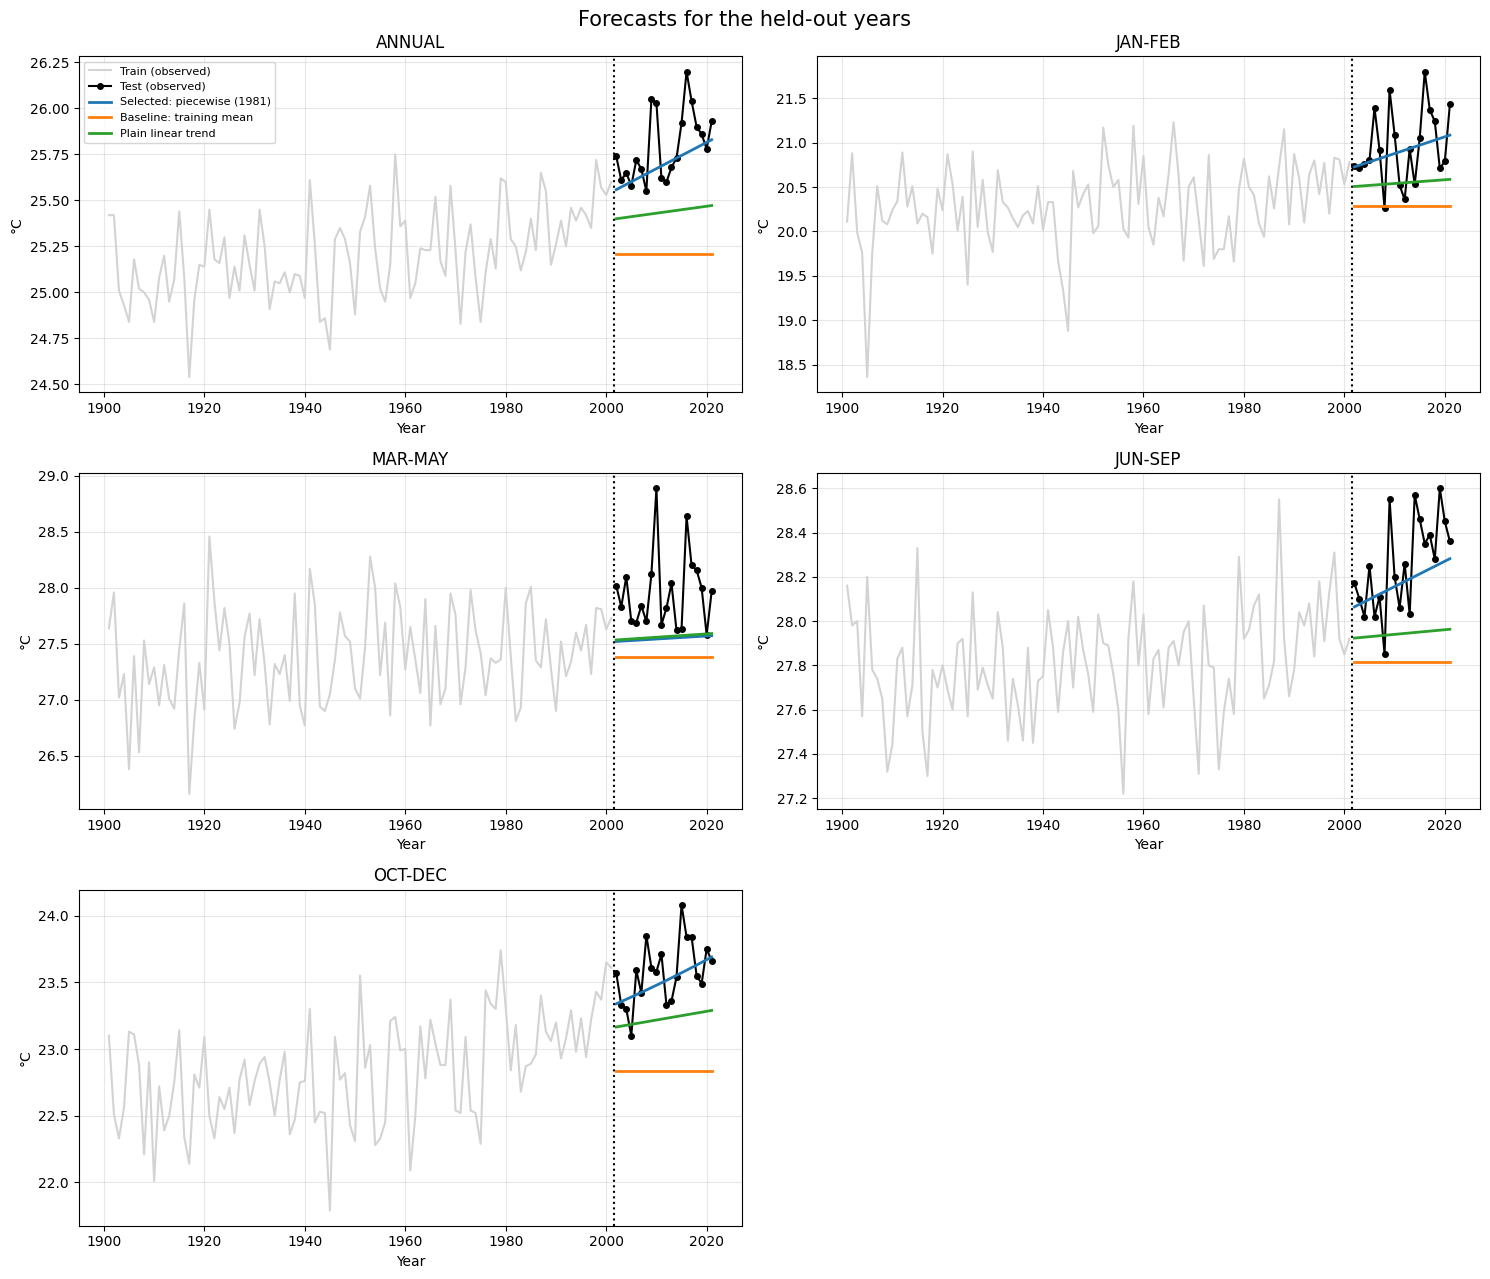

Selected model beats the training-mean baseline (test RMSE) in 5 of 5 series.
Series with negative test R² for the selected model: ['ANNUAL', 'MAR-MAY']


In [27]:
fig, axes = plt.subplots(3, 2, figsize=(15, 13)); axes = axes.flatten()
for i, col in enumerate(temperature_columns):
    axes[i].plot(train["YEAR"], train[col], color="lightgray", label="Train (observed)")
    axes[i].plot(test["YEAR"], test[col], "ko-", ms=4, label="Test (observed)")
    for name, p in test_preds[col].items():
        axes[i].plot(test["YEAR"], p, lw=2, label=name)
    axes[i].axvline(test["YEAR"].min() - 0.5, color="black", ls=":")
    axes[i].set_title(col); axes[i].set_xlabel("Year"); axes[i].set_ylabel("°C")
    axes[i].grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.delaxes(axes[5]); plt.suptitle("Forecasts for the held-out years", fontsize=15)
plt.tight_layout(); plt.show()

# Summary produced by code (nothing typed by hand)
sel_rows = holdout[holdout["Model"].str.startswith("Selected")].set_index("Series")
base_rows = holdout[holdout["Model"].str.startswith("Baseline")].set_index("Series")
beats = (sel_rows["RMSE"] < base_rows["RMSE"]).loc[temperature_columns]
print(f"Selected model beats the training-mean baseline (test RMSE) in {int(beats.sum())} of {len(beats)} series.")
neg = sel_rows.loc[sel_rows["R²"] < 0, :].index.tolist()
print("Series with negative test R² for the selected model:", neg if neg else "none")

### 5.1 How to read these results
- The **training-mean baseline** is poor because temperature has a clear upward trend, so a model that ignores time under-predicts every recent year.
- A **plain linear trend** also lags behind in the test period when warming has accelerated, so models that allow the slope to change (piecewise, or a higher-degree polynomial) do better for most series. **MAR-MAY is the exception**: no candidate clearly improves on a straight line there, and its test R² is strongly negative, so forecasts for that season are the least reliable.
- Test R² is measured within a short 20-year window where the variation is small, so it can be low or negative even when MAE and RMSE are small. MAE and RMSE (in °C) are therefore the more informative numbers here; R² is reported for completeness.
- Only 121 yearly values and a single predictor (`YEAR`) are available. These are **trend-extrapolation** models, not physical climate models, and they should not be used for long-range forecasts.

## 6. Has warming accelerated? (inference on the full period)
A continuous piecewise-linear regression with a slope change at 1981, fitted on all years, with HAC standard errors. This part answers a *descriptive* question and is separate from the forecasting task in Section 5. A sensitivity check moves the breakpoint to 1971 and 1991 to show how much the conclusion depends on that choice.

In [28]:
def piecewise_fit(series, break_year, robust=True):
    t = (df["YEAR"] - 1901) / 10
    X = sm.add_constant(pd.DataFrame({"TIME_DECADE": t,
                                      "POST_BREAK": np.maximum(df["YEAR"] - break_year, 0) / 10}))
    ols = sm.OLS(series, X)
    return ols.fit(cov_type="HAC", cov_kwds={"maxlags": 5}) if robust else ols.fit()

rows = []
for bp in (1971, 1981, 1991):
    for col in temperature_columns:
        m = piecewise_fit(df[col], bp)
        early, change = m.params["TIME_DECADE"], m.params["POST_BREAK"]
        ci = m.conf_int().loc["POST_BREAK"]
        rows.append({"Breakpoint": bp, "Series": col,
                     "Early slope (°C/dec)": early, "Recent slope (°C/dec)": early + change,
                     "Slope change": change, "CI low": ci.iloc[0], "CI high": ci.iloc[1],
                     "p-value": m.pvalues["POST_BREAK"], "In-sample R²": m.rsquared})
accel = pd.DataFrame(rows)
print("Warming-rate comparison (slope change after the breakpoint)")
display(accel.round(4))

Warming-rate comparison (slope change after the breakpoint)


,Breakpoint,Series,Early slope (°C/dec),Recent slope (°C/dec),Slope change,CI low,CI high,p-value,In-sample R²
0,1971,ANNUAL,0.0149,0.1418,0.1269,0.0869,0.1670,0.0000,0.5981
1,1971,JAN-FEB,0.0150,0.1621,0.1472,0.0458,0.2485,0.0044,0.2827
2,1971,MAR-MAY,0.0207,0.1175,0.0967,0.0295,0.1640,0.0048,0.2166
3,1971,JUN-SEP,-0.0032,0.1197,0.1229,0.0766,0.1692,0.0000,0.4101
4,1971,OCT-DEC,0.0329,0.1831,0.1502,0.0911,0.2094,0.0000,0.5402
5,1981,ANNUAL,0.0233,0.1744,0.1511,0.1120,0.1902,0.0000,0.6082
6,1981,JAN-FEB,0.0232,0.2044,0.1812,0.0835,0.2790,0.0003,0.2920
7,1981,MAR-MAY,0.0221,0.1566,0.1344,0.0669,0.2019,0.0001,0.2314
8,1981,JUN-SEP,0.0065,0.1467,0.1402,0.0884,0.1920,0.0000,0.4099
9,1981,OCT-DEC,0.0470,0.2100,0.1630,0.0855,0.2405,0.0000,0.5330


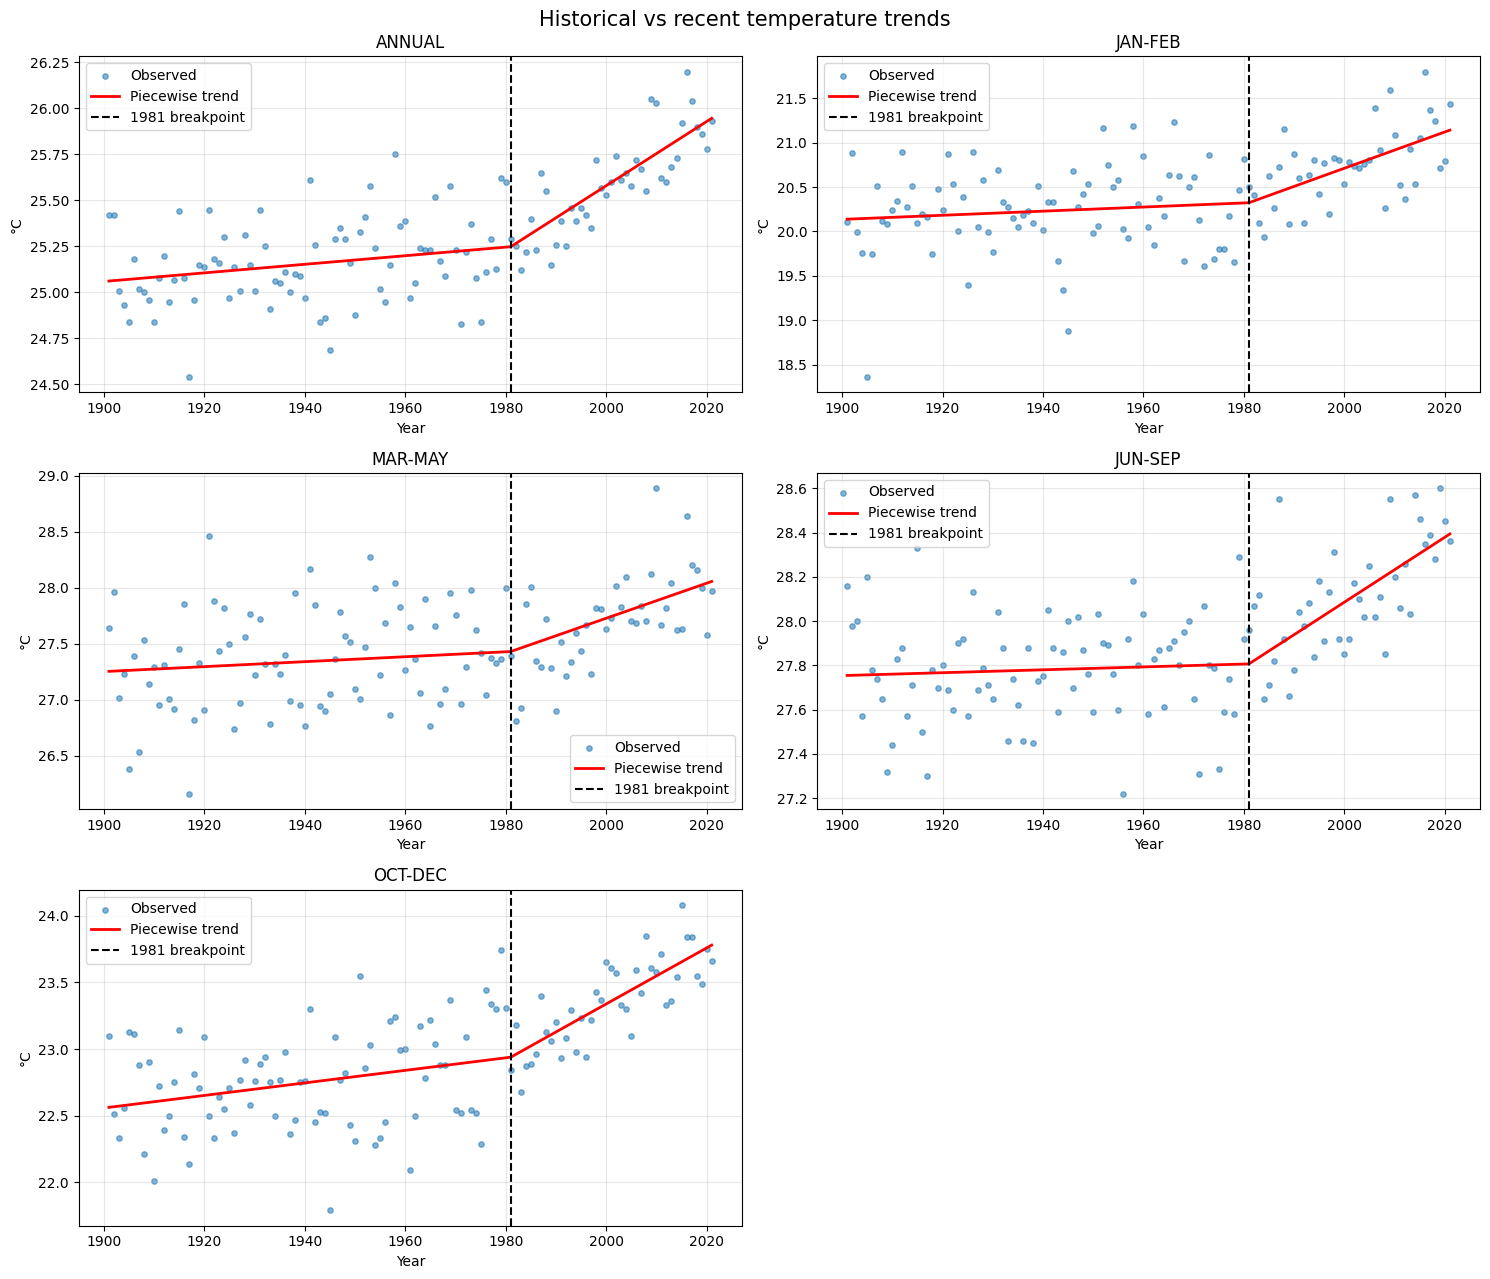

In [29]:
fig, axes = plt.subplots(3, 2, figsize=(15, 13)); axes = axes.flatten()
for i, col in enumerate(temperature_columns):
    m = piecewise_fit(df[col], BREAK_YEAR, robust=False)
    axes[i].scatter(df["YEAR"], df[col], s=15, alpha=0.55, label="Observed")
    axes[i].plot(df["YEAR"], m.predict(m.model.exog), color="red", lw=2, label="Piecewise trend")
    axes[i].axvline(BREAK_YEAR, color="black", ls="--", label=f"{BREAK_YEAR} breakpoint")
    axes[i].set_title(col); axes[i].set_xlabel("Year"); axes[i].set_ylabel("°C")
    axes[i].grid(alpha=0.3); axes[i].legend()
fig.delaxes(axes[5]); plt.suptitle("Historical vs recent temperature trends", fontsize=15)
plt.tight_layout(); plt.show()

## 7. Residual diagnostics for the piecewise model

,Series,Residual std,Durbin-Watson,Ljung-Box p (lag 5),Ljung-Box p (lag 10)
0,ANNUAL,0.1981,1.5822,0.0003,0.0002
1,JAN-FEB,0.4375,1.8439,0.5263,0.6382
2,MAR-MAY,0.4079,1.9639,0.3720,0.1948
3,JUN-SEP,0.2198,1.9853,0.6957,0.7849
4,OCT-DEC,0.3148,1.7722,0.0262,0.2138


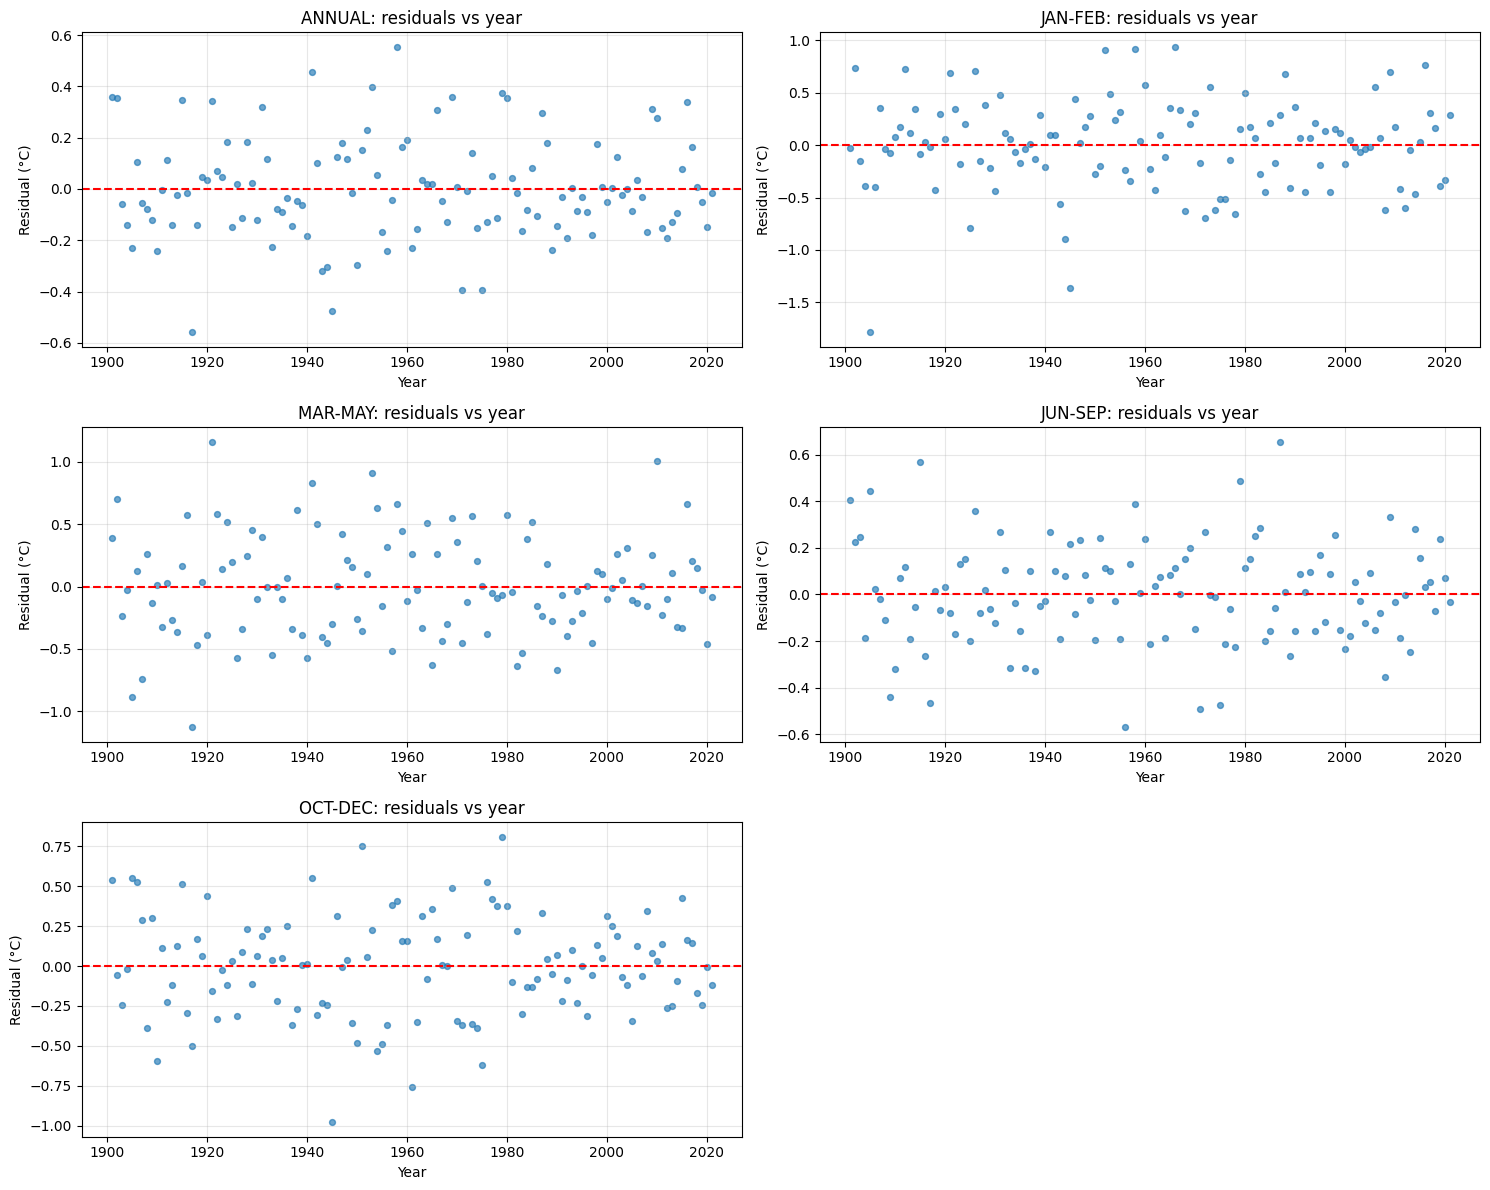

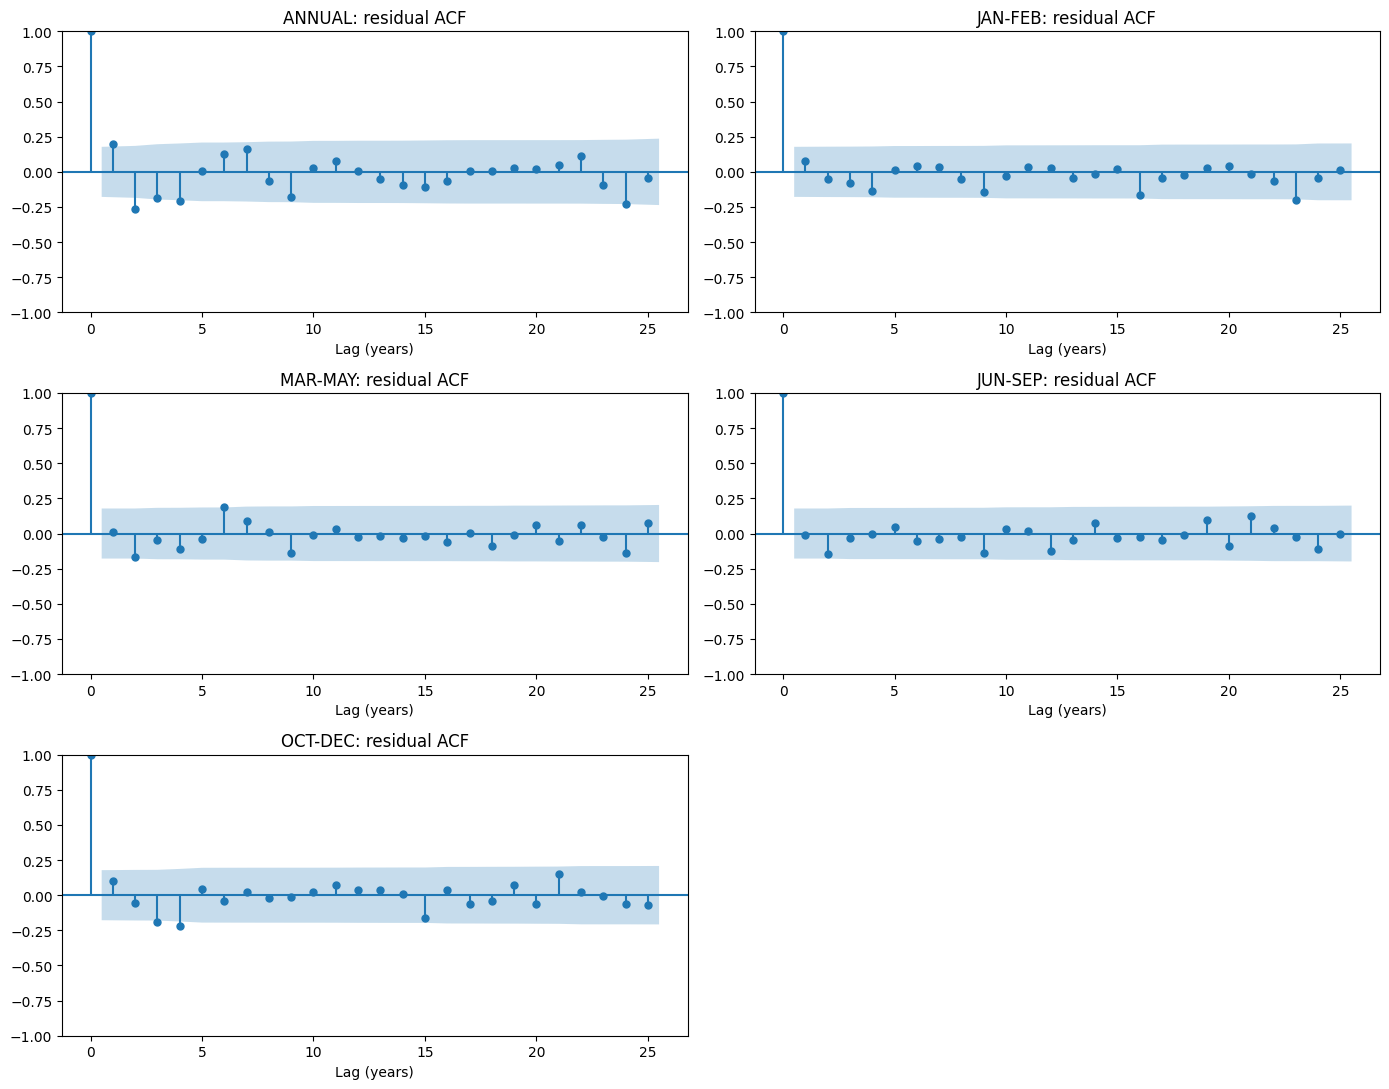

In [30]:
residual_store, rows = {}, []
for col in temperature_columns:
    m = piecewise_fit(df[col], BREAK_YEAR, robust=False)
    res = m.resid.values
    residual_store[col] = res
    lb = acorr_ljungbox(res, lags=[5, 10], return_df=True)
    rows.append({"Series": col, "Residual std": res.std(ddof=1),
                 "Durbin-Watson": durbin_watson(res),
                 "Ljung-Box p (lag 5)": lb.loc[5, "lb_pvalue"],
                 "Ljung-Box p (lag 10)": lb.loc[10, "lb_pvalue"]})
display(pd.DataFrame(rows).round(4))

fig, axes = plt.subplots(3, 2, figsize=(15, 12)); axes = axes.flatten()
for i, col in enumerate(temperature_columns):
    axes[i].scatter(df["YEAR"], residual_store[col], s=18, alpha=0.65)
    axes[i].axhline(0, color="red", ls="--")
    axes[i].set_title(f"{col}: residuals vs year"); axes[i].set_xlabel("Year"); axes[i].set_ylabel("Residual (°C)")
    axes[i].grid(alpha=0.3)
fig.delaxes(axes[5]); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 2, figsize=(14, 11)); axes = axes.flatten()
for i, col in enumerate(temperature_columns):
    plot_acf(residual_store[col], lags=25, ax=axes[i], alpha=0.05)
    axes[i].set_title(f"{col}: residual ACF"); axes[i].set_xlabel("Lag (years)")
fig.delaxes(axes[5]); plt.tight_layout(); plt.show()

## 8. Conclusions and limitations
**What the analysis supports (see the tables above for the numbers):**
- Every series shows a statistically significant upward trend over 1901–2021 (Section 4.1).
- Allowing the slope to change after the breakpoint gives a higher in-sample R² than a single straight line (compare Section 4.1 with Section 6), and the estimated slope change is positive for every series at the 1971, 1981 and 1991 breakpoints (Section 6).
- In the 2002–2021 hold-out period, the CV-selected model is compared directly with a no-trend baseline and a plain linear trend (Section 5). The size of the improvement, and the series where R² stays low or negative (notably MAR-MAY), are in the held-out table.

**Limitations.**
- Only 121 annual values and a single predictor; the models extrapolate a trend and ignore physical drivers such as greenhouse gases, aerosols or monsoon variability.
- The test set has only 20 points, so test metrics are noisy. Time-series CV folds of 10 years are also small.
- Residuals of the annual series show some autocorrelation (Section 7), so p-values rely on HAC corrections and should be read with care.
- The 1981 breakpoint is a modelling choice; the sensitivity check shows how much the results depend on it.
- Dataset source and licence must be stated (see the TODO in Section 1).

**Possible extensions.** Block bootstrap intervals for the slopes, a rolling-origin evaluation with more test windows, and models with additional predictors (e.g. CO₂ concentration, ENSO index).